Name: Nadya Angelie Lislie

NIM: [removed] -> B dataset

**This notebook answers the following questions:**

Number 2

a.
(5 points) The dataset has yet to be analyzed. Analyze it & state any discovered issues! Also, handle the
issues found in the dataset & provide reasons for your methods in dealing with each issue!

b. (10 points) Build an Artificial Neural Network (ANN) with 3 hidden layers. Each hidden layer should
use sigmoid as its activation function. The number of neurons in the first hidden layer should be 512 and
each of the subsequent layers will have N/2 neurons where N is the number of neurons in the previous
layer. Train the model for at least 20 epochs & analyze the train-validation losses!

c.
(10 points) Modify the architecture of the ANN model or fine-tune it to obtain a model with lower best
validation loss. Explain the reasons behind your modifications!
d. (15 points) Evaluate both models on a test dataset. Analyze the results & make a clear conclusion!

**Explanation Video Link:**

https://drive.google.com/drive/folders/1DltwoBtwpm1km1QECec-f2QNSxiZkJBh?usp=drive_link

# **We start from the raw `2B.parquet` dataset**

In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

# For reproducibility
RANDOM_STATE = 1234
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# I will load the dataset
df = pd.read_parquet("2B.parquet")
df.head()

,Sales_ID,name,year,selling_price,Region,State or Province,City,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,4333,Maruti,2018,6000.0,Central,Nebraska,Norfolk,Petrol,Dealer,Automatic,First_Owner,22.0,1197,81.80,113Nm@ 4200rpm,5
1,5562,Tata,2012,1400.0,Central,Illinois,Bloomington,Diesel,Individual,Manual,Fourth_Above_Owner,19.09,1396,69.00,135Nm@ 2500rpm,5
2,6854,Chevrolet,2015,4340.0,East,New York,Schenectady,Diesel,Individual,Manual,First_Owner,13.58,2499,72.40,171Nm@ 1800rpm,10
3,8113,Ford,2018,7460.0,South,North Carolina,Mooresville,Diesel,Individual,Manual,First_Owner,24.4,1498,98.63,215Nm@ 1750-3000rpm,5
4,6986,Tata,2017,3700.0,East,Maryland,Silver Spring,Petrol,Individual,Manual,First_Owner,17.57,1193,88.70,140Nm@ 1500-4000rpm,5


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Sales_ID           4200 non-null   int64  
 1   name               4200 non-null   object 
 2   year               4200 non-null   int64  
 3   selling_price      4199 non-null   float64
 4   Region             4200 non-null   object 
 5   State or Province  4200 non-null   object 
 6   City               4200 non-null   object 
 7   fuel               4200 non-null   object 
 8   seller_type        4200 non-null   object 
 9   transmission       4200 non-null   object 
 10  owner              4200 non-null   object 
 11  mileage            4200 non-null   object 
 12  engine             4200 non-null   int64  
 13  max_power          4200 non-null   float64
 14  torque             4200 non-null   object 
 15  seats              4200 non-null   int64  
dtypes: float64(2), int64(4),

# **A. Data Cleaning and Preparation**

## 1. Initial Exploration & Data Issues Including Cleaning

In [ ]:
df_clean = df.copy()

In [ ]:
# I always check for duplicates first in data cleaning process
exact_dups = df_clean.duplicated().sum()
print(exact_dups)

# Now, Im checking duplicates of sales ID
sales_id_dups = df_clean.duplicated(subset=['Sales_ID']).sum()
print(sales_id_dups)

# Results show no duplicate so no need to be cleaned

0
0


In [ ]:
print(df_clean.shape)
print(df_clean.dtypes)

(4200, 16)
Sales_ID               int64
name                  object
year                   int64
selling_price        float64
Region                object
State or Province     object
City                  object
fuel                  object
seller_type           object
transmission          object
owner                 object
mileage               object
engine                 int64
max_power            float64
torque                object
seats                  int64
dtype: object


From the dtypes above we see that:
- Most numerical variables such as Sales_ID, year, engine, seats, and selling_price are correctly stored in numeric formats (int64 or float64).
- Several important variables (mileage and torque) appear to be stored as object types, suggesting they may contain mixed units or non-numeric characters. These will likely need cleaning and conversion into numeric formats for analysis.
- Categorical fields such as fuel, seller_type, transmission, owner, Region, State or Province, and City are appropriately classified as object types. So, no need for fixing

I will analyse the three columns that I think should not be object data type first:

In [ ]:
df_clean['mileage'].value_counts()

,count
mileage,
18.9,126
19.7,94
18.6,92
21.1,77
17.0,69
...,...
"23,95",1
10.8,1
21.14,1


In [ ]:
# mileage is stored as string but already all in numbers ("22.0 etc"), I will convert it to numeric
df_clean['mileage'] = pd.to_numeric(df_clean['mileage'], errors='coerce')

In [ ]:
df_clean['torque'].value_counts()

,count
torque,
190Nm@ 2000rpm,294
200Nm@ 1750rpm,253
90Nm@ 3500rpm,221
113Nm@ 4200rpm,101
62Nm@ 3000rpm,90
...,...
99.1Nm@ 4500rpm,1
400nm@ 2800rpm,1
98Nm@ 1600-3000rpm,1


In [ ]:
df_clean['torque'] = (
    df_clean['torque']
    .astype(str)
    .str.lower()
    .str.replace(',', '', regex=False)
    .str.strip()
)

df_clean['torque_nm'] = (
    df_clean['torque']
    .str.extract(r'(\d+\.?\d*)')[0]
    .astype(float)
)

df_clean['torque_rpm'] = df_clean['torque'].str.extract(
    r'@ *(\d+\.?\d*)'
)[0].astype(float)

rpm_range = df_clean['torque'].str.extract(
    r'@ *(\d+\.?\d*) *(?:-|–|to|—) *(\d+\.?\d*)'
).astype(float)

df_clean.loc[rpm_range[0].notna(), 'torque_rpm'] = rpm_range.mean(axis=1)

fallback_rpm = df_clean['torque'].str.extract(
    r'(\d+)\s*(?:rpm|r)$'
)[0].astype(float)

df_clean['torque_rpm'] = df_clean['torque_rpm'].fillna(fallback_rpm)

two_numbers = df_clean['torque'].str.extractall(r'(\d+\.?\d*)').unstack()
second_number = two_numbers.get(1)

if isinstance(second_number, pd.Series):
    df_clean['torque_rpm'] = df_clean['torque_rpm'].fillna(second_number.astype(float))

kgm_mask = df_clean['torque'].str.contains('kgm', na=False)
df_clean.loc[kgm_mask, 'torque_nm'] = df_clean.loc[kgm_mask, 'torque_nm'] * 9.80665

In [ ]:
# Looks like I have finally extracted the torque correctly
df_clean.head(15)

,Sales_ID,name,year,selling_price,Region,State or Province,City,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,torque_nm,torque_rpm
0,4333,Maruti,2018,6000.00,Central,Nebraska,Norfolk,Petrol,Dealer,Automatic,First_Owner,22.00,1197,81.80,113nm@ 4200rpm,5,113.0,4200.0
1,5562,Tata,2012,1400.00,Central,Illinois,Bloomington,Diesel,Individual,Manual,Fourth_Above_Owner,19.09,1396,69.00,135nm@ 2500rpm,5,135.0,2500.0
2,6854,Chevrolet,2015,4340.00,East,New York,Schenectady,Diesel,Individual,Manual,First_Owner,13.58,2499,72.40,171nm@ 1800rpm,10,171.0,1800.0
3,8113,Ford,2018,7460.00,South,North Carolina,Mooresville,Diesel,Individual,Manual,First_Owner,24.40,1498,98.63,215nm@ 1750-3000rpm,5,215.0,2375.0
4,6986,Tata,2017,3700.00,East,Maryland,Silver Spring,Petrol,Individual,Manual,First_Owner,17.57,1193,88.70,140nm@ 1500-4000rpm,5,140.0,2750.0
5,6833,Hyundai,2015,5099.99,West,California,Lemon Grove,Diesel,Individual,Manual,Second_Owner,24.40,1120,71.00,180.4nm@ 1750-2500rpm,5,180.4,2125.0
6,4467,Hyundai,2015,5750.00,Central,Iowa,Ottumwa,Diesel,Individual,Manual,First_Owner,22.54,1396,88.73,219.7nm@ 1500-2750rpm,5,219.7,2125.0
7,3029,Hyundai,2017,6250.00,South,Virginia,Tysons Corner,Petrol,Individual,Manual,First_Owner,18.60,1197,81.83,114.7nm@ 4000rpm,5,114.7,4000.0
8,3502,Chevrolet,2011,1500.00,South,Tennessee,Columbia,Petrol,Individual,Manual,First_Owner,18.00,995,62.00,90.3nm@ 4200rpm,5,90.3,4200.0
9,5853,Maruti,2018,8510.00,South,Georgia,Hinesville,Diesel,Individual,Automatic,First_Owner,28.40,1248,74.02,190nm@ 2000rpm,5,190.0,2000.0


In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Sales_ID           4200 non-null   int64  
 1   name               4200 non-null   object 
 2   year               4200 non-null   int64  
 3   selling_price      4199 non-null   float64
 4   Region             4200 non-null   object 
 5   State or Province  4200 non-null   object 
 6   City               4200 non-null   object 
 7   fuel               4200 non-null   object 
 8   seller_type        4200 non-null   object 
 9   transmission       4200 non-null   object 
 10  owner              4200 non-null   object 
 11  mileage            4198 non-null   float64
 12  engine             4200 non-null   int64  
 13  max_power          4200 non-null   float64
 14  torque             4200 non-null   object 
 15  seats              4200 non-null   int64  
 16  torque_nm          4200 

In [ ]:
(4200-4181)/4200
# There is a small amount of missing value in torque_rpm

0.004523809523809524

In [ ]:
# I'll use median because its very small that imputation can be harmless and using median is statistically valid
df_clean['torque_rpm'] = df_clean.groupby('fuel')['torque_rpm'].transform(
    lambda x: x.fillna(x.median())
)

In [ ]:
missing = df_clean.isnull().sum().sort_values(ascending=False)
print(missing[missing > 0])

mileage          2
selling_price    1
dtype: int64


In [ ]:
# I use dropna because there is only 1 and 2 missing value (less than 20%)
df_clean = df_clean.dropna(subset=['selling_price', 'mileage'])

Now I am checking consistencies of the categorical variables:

In [ ]:
df_clean['Region'].value_counts()

,count
Region,
Central,1311
East,1019
West,1014
South,853


In [ ]:
df_clean['State or Province'].value_counts()

,count
State or Province,
California,484
Texas,287
Illinois,264
New York,253
Florida,212
Ohio,184
Michigan,156
Washington,151
North Carolina,118


In [ ]:
df_clean['City'].value_counts()

,count
City,
Los Angeles,95
New York City,93
Chicago,54
Seattle,45
Boston,35
...,...
Wellesley,1
Laconia,1
Westerly,1


In [ ]:
df_clean['fuel'].value_counts()
# There is a suspicious 3 values of blank, need cleaning

,count
fuel,
Diesel,2320
Petrol,1826
CNG,30
LPG,18
,3


In [ ]:
# I'm changing all the black into nan value
df_clean['fuel'] = df_clean['fuel'].astype(str).str.strip().replace({'': np.nan, 'nan': np.nan})
print(df_clean['fuel'].value_counts(dropna=False))
# These newly discovered nan will be cleaned later, I want to check all object type value first

fuel
Diesel    2320
Petrol    1826
CNG         30
LPG         18
NaN          3
Name: count, dtype: int64


In [ ]:
df_clean['seller_type'].value_counts()

,count
seller_type,
Individual,3470
Dealer,610
Trustmark_Dealer,117


In [ ]:
df_clean['transmission'].value_counts()

,count
transmission,
Manual,3614
Automatic,583


In [ ]:
df_clean['owner'].value_counts()

,count
owner,
First_Owner,2804
Second_Owner,1045
Third_Owner,267
Fourth_Above_Owner,78
Test_Drive_Car,3


In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4197 entries, 0 to 4199
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Sales_ID           4197 non-null   int64  
 1   name               4197 non-null   object 
 2   year               4197 non-null   int64  
 3   selling_price      4197 non-null   float64
 4   Region             4197 non-null   object 
 5   State or Province  4197 non-null   object 
 6   City               4197 non-null   object 
 7   fuel               4194 non-null   object 
 8   seller_type        4197 non-null   object 
 9   transmission       4197 non-null   object 
 10  owner              4197 non-null   object 
 11  mileage            4197 non-null   float64
 12  engine             4197 non-null   int64  
 13  max_power          4197 non-null   float64
 14  torque             4197 non-null   object 
 15  seats              4197 non-null   int64  
 16  torque_nm          4197 non-n

In [ ]:
# Okay, now I will drop the nan value of fuel because it's <20%
df_clean = df_clean.dropna(subset=['fuel'])

Let's see the desc stats for our numerical columns:

In [ ]:
num_cols = ['year', 'selling_price', 'mileage', 'engine', 'max_power', 'seats', 'torque_nm', 'torque_rpm']
desc = df_clean[num_cols].describe()
print(desc)

              year  selling_price      mileage       engine    max_power  \
count  4194.000000    4194.000000  4194.000000  4194.000000  4194.000000   
mean   2014.288984    6667.414220    19.484077  1451.871483    91.720546   
std      15.900536    8478.326974     4.393742   493.569785    35.917669   
min    1994.000000     299.990000  -100.000000   624.000000    32.800000   
25%    2012.000000    2700.000000    16.800000  1197.000000    68.050000   
50%    2015.000000    4554.995000    19.400000  1248.000000    82.850000   
75%    2017.000000    7000.000000    22.370000  1582.000000   102.000000   
max    3014.000000  100000.000000    42.000000  3604.000000   400.000000   

             seats    torque_nm    torque_rpm  
count  4194.000000  4194.000000   4194.000000  
mean      5.401288   182.963818   2875.101097  
std       0.945905   124.468606   1008.070730  
min       2.000000    48.000000   1300.000000  
25%       5.000000   111.800000   2000.000000  
50%       5.000000   173.00

The table above provides summary statistics for six numerical variables:

- Year = ranges from 1994 to an outlier of 3014, indicating the presence of incorrect or future-year data that should be cleaned.

- Selling Price = range widely from about 300 to 100,000, with a mean of ~6664. The large standard deviation (8474) indicates substantial variability, likely due to differences in brand, model, and vehicle condition. One missing value is noted (count = 4199). Will check for outliers later

- Mileage = range from –100 to 42. The problem is that negative mileage values are impossible. Willdo a clean up for this later.

- Engine = varies from 624 cc to 3604 cc, with a median of 1248 cc. This reflects a mix of small hatchback engines and larger SUVs.

- Max Power = ranges from 32.8 to 400, with an average around 91.7. The relatively high spread (std ≈ 35.9) suggests a diverse set of vehicle types and performance levels.

- Seats = most vehicles have 5 seats (based on the 25th, 50th, and 75th percentiles all being 5). Outliers exist, with seat counts ranging from 2 to 14, likely representing sports cars and large passenger vans.

- Torque Nm = range from 173 to 3726. Quite reasonable spread showing typical torque. But 3726.5 Nm is mechanically impossible for any vehicle in this dataset.

- Torque RPM = range from 1300 to 21800. The value 21800 is mechanically impossible for a torque peak in any automotive engine.

In [ ]:
# We see unrealistic max, which is 3014 and with this value counts belowm there is only one unrealistic data
df_clean['year'].value_counts()

,count
year,
2017,533
2016,463
2018,436
2015,419
2013,359
2012,334
2014,332
2019,307
2011,288


In [ ]:
# Only one wierd value. It is save to assume that its a typoo from 2014 to 3014 so I will replace that value
df_clean['year'] = df_clean['year'].replace(3014, 2014)

<Axes: >

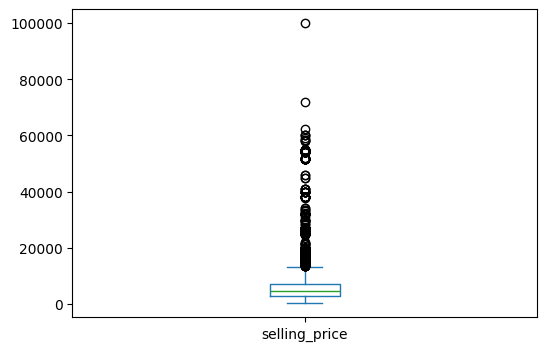

In [ ]:
df_clean['selling_price'].plot(kind='box', figsize=(6,4))

In [ ]:
Q1 = df_clean['selling_price'].quantile(0.25)
Q3 = df_clean['selling_price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

outliers = df_clean[(df_clean['selling_price'] < lower_bound) | (df_clean['selling_price'] > upper_bound)]
print("Outlier count:", len(outliers))

Lower bound: -3750.0
Upper bound: 13450.0
Outlier count: 330


In [ ]:
330/4197*100
# usually higher than 5% is not that good if left uncleaned

7.86275911365261

The thing is, outliers in selling price are likely real and not error. I dont want to lose this valuable information by dropping the outliers. That is why I am picking winsorization to preserve the sample size while stabilizing the model, still keeps the distribution realistic.

In [ ]:
lower_cap = Q1 - 1.5 * IQR
upper_cap = Q3 + 1.5 * IQR

# Winsorize (cap the values)
df_clean['selling_price_capped'] = df_clean['selling_price'].clip(lower=lower_cap, upper=upper_cap)

<Axes: >

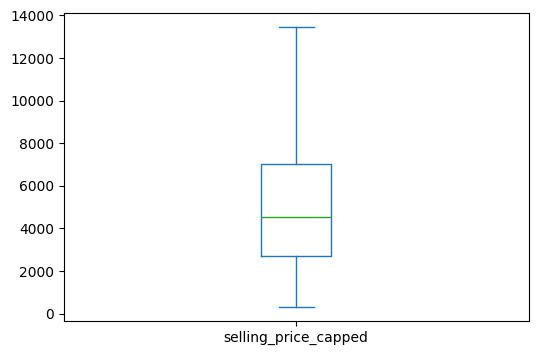

In [ ]:
df_clean['selling_price_capped'].plot(kind='box', figsize=(6,4))

In [ ]:
# onto the mileage, it cannot be a negative numbers
negative_mileage_count = (df_clean['mileage'] < 0).sum()
print(negative_mileage_count)

1


In [ ]:
df_clean = df_clean[(df_clean['mileage'] >= 0)]

In [ ]:
df_clean[df_clean['torque_nm'] > 1000]

,Sales_ID,name,year,selling_price,Region,State or Province,City,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,torque_nm,torque_rpm,selling_price_capped
393,7744,Maruti,2009,2500.0,West,Arizona,Prescott Valley,Petrol,Individual,Manual,Second_Owner,15.0,1586,104.68,145@ 4100(kgm@ rpm),5,1421.96425,4100.0,2500.0
507,779,Ford,2013,10750.0,Central,Michigan,Detroit,Diesel,Individual,Automatic,Third_Owner,12.8,2953,156.00,380nm(38.7kgm)@ 2500rpm,7,3726.52700,2500.0,10750.0
1089,2290,Maruti,2010,3000.0,West,California,Claremont,Petrol,Individual,Manual,First_Owner,15.0,1586,104.68,145@ 4100(kgm@ rpm),5,1421.96425,4100.0,3000.0
1711,1212,Maruti,2007,1600.0,South,Alabama,Madison,Petrol,Individual,Manual,Second_Owner,15.0,1586,104.68,145@ 4100(kgm@ rpm),5,1421.96425,4100.0,1600.0
1787,4997,Mahindra,2010,2000.0,West,Utah,Pleasant Grove,Petrol,Individual,Manual,First_Owner,15.7,1390,75.00,110@ 3000(kgm@ rpm),5,1078.73150,3000.0,2000.0
2016,4455,Tata,2006,1300.0,Central,Minnesota,Cottage Grove,Diesel,Individual,Manual,First_Owner,13.7,1948,68.00,115@ 2500(kgm@ rpm),7,1127.76475,2500.0,1300.0
2188,2087,Tata,2012,2000.0,South,Kentucky,Danville,Diesel,Individual,Manual,First_Owner,12.2,1948,68.00,115@ 2500(kgm@ rpm),10,1127.76475,2500.0,2000.0
2432,5416,Tata,2005,2250.0,West,Washington,Lynnwood,Diesel,Individual,Manual,First_Owner,12.3,1948,90.00,190@ 21800(kgm@ rpm),7,1863.26350,21800.0,2250.0
2803,7667,Tata,2008,1500.0,Central,Michigan,Warren,Diesel,Individual,Manual,First_Owner,12.2,1948,68.00,115@ 2500(kgm@ rpm),9,1127.76475,2500.0,1500.0
3220,5243,Tata,2008,2000.0,Central,Michigan,Lansing,Diesel,Individual,Manual,First_Owner,12.2,1948,68.00,115@ 2500(kgm@ rpm),10,1127.76475,2500.0,2000.0


In [ ]:
df_wrong = df_clean[df_clean['torque_nm'] > 500]
df_wrong[['torque', 'torque_nm']].head()

,torque,torque_nm
65,620nm@ 1500-2500rpm,620.00000
127,600nm@ 2000rpm,600.00000
393,145@ 4100(kgm@ rpm),1421.96425
507,380nm(38.7kgm)@ 2500rpm,3726.52700
600,620nm@ 1600-2400rpm,620.00000


In [ ]:
df_clean.loc[df_clean['torque_nm'] > 500, 'torque_nm'] /= 10

In [ ]:
df_clean[df_clean['torque_nm'] > 500].shape

(0, 19)

In [ ]:
df_clean[df_clean['torque_rpm'] > 5000]

,Sales_ID,name,year,selling_price,Region,State or Province,City,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,torque_nm,torque_rpm,selling_price_capped
2432,5416,Tata,2005,2250.0,West,Washington,Lynnwood,Diesel,Individual,Manual,First_Owner,12.3,1948,90.0,190@ 21800(kgm@ rpm),7,186.32635,21800.0,2250.0


In [ ]:
df_clean.loc[df_clean['torque_rpm'] == 21800, 'torque_rpm'] = 2180

In [ ]:
print(df_clean[['torque_nm', 'torque_rpm']].describe())
# finally the torque is cleaned

         torque_nm   torque_rpm
count  4193.000000  4193.000000
mean    175.914365  2870.153589
std      86.338678   964.780261
min      48.000000  1300.000000
25%     111.795810  2000.000000
50%     171.000000  2400.000000
75%     205.000000  4000.000000
max     500.000000  5000.000000


In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4193 entries, 0 to 4199
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Sales_ID              4193 non-null   int64  
 1   name                  4193 non-null   object 
 2   year                  4193 non-null   int64  
 3   selling_price         4193 non-null   float64
 4   Region                4193 non-null   object 
 5   State or Province     4193 non-null   object 
 6   City                  4193 non-null   object 
 7   fuel                  4193 non-null   object 
 8   seller_type           4193 non-null   object 
 9   transmission          4193 non-null   object 
 10  owner                 4193 non-null   object 
 11  mileage               4193 non-null   float64
 12  engine                4193 non-null   int64  
 13  max_power             4193 non-null   float64
 14  torque                4193 non-null   object 
 15  seats                 4193

In [ ]:
4193/4200*100
# Very little data are gone

99.83333333333333

In [ ]:
output_csv = "2B_cleaned.csv"
df_clean.to_csv(output_csv, index=False)

## 2. Encoding, Scaling & Dataset Spliting

In [ ]:
df_model = pd.read_csv("2B_cleaned.csv")
df_model.head()

,Sales_ID,name,year,selling_price,Region,State or Province,City,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,torque_nm,torque_rpm,selling_price_capped
0,4333,Maruti,2018,6000.0,Central,Nebraska,Norfolk,Petrol,Dealer,Automatic,First_Owner,22.00,1197,81.80,113nm@ 4200rpm,5,113.0,4200.0,6000.0
1,5562,Tata,2012,1400.0,Central,Illinois,Bloomington,Diesel,Individual,Manual,Fourth_Above_Owner,19.09,1396,69.00,135nm@ 2500rpm,5,135.0,2500.0,1400.0
2,6854,Chevrolet,2015,4340.0,East,New York,Schenectady,Diesel,Individual,Manual,First_Owner,13.58,2499,72.40,171nm@ 1800rpm,10,171.0,1800.0,4340.0
3,8113,Ford,2018,7460.0,South,North Carolina,Mooresville,Diesel,Individual,Manual,First_Owner,24.40,1498,98.63,215nm@ 1750-3000rpm,5,215.0,2375.0,7460.0
4,6986,Tata,2017,3700.0,East,Maryland,Silver Spring,Petrol,Individual,Manual,First_Owner,17.57,1193,88.70,140nm@ 1500-4000rpm,5,140.0,2750.0,3700.0


In [ ]:
df_model.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4193 entries, 0 to 4192
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Sales_ID              4193 non-null   int64  
 1   name                  4193 non-null   object 
 2   year                  4193 non-null   int64  
 3   selling_price         4193 non-null   float64
 4   Region                4193 non-null   object 
 5   State or Province     4193 non-null   object 
 6   City                  4193 non-null   object 
 7   fuel                  4193 non-null   object 
 8   seller_type           4193 non-null   object 
 9   transmission          4193 non-null   object 
 10  owner                 4193 non-null   object 
 11  mileage               4193 non-null   float64
 12  engine                4193 non-null   int64  
 13  max_power             4193 non-null   float64
 14  torque                4193 non-null   object 
 15  seats                

In [ ]:
drop_cols = ["Sales_ID", "torque"]  # ID + raw text
for col in ["City", "State or Province"]:  # drop high-cardinality location detail
    if col in df_model.columns:
        drop_cols.append(col)


df_model = df_model.drop(columns=drop_cols, errors="ignore")

In [ ]:
y = df_model["selling_price"]
X = df_model.drop(columns=["selling_price"])

In [ ]:
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()

print(categorical_cols)
print(numeric_cols)

['name', 'Region', 'fuel', 'seller_type', 'transmission', 'owner']
['year', 'mileage', 'engine', 'max_power', 'seats', 'torque_nm', 'torque_rpm', 'selling_price_capped']


In [ ]:
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

In [ ]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=RANDOM_STATE
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=RANDOM_STATE
)  # 0.25 * 0.8 = 0.2

print("Train shape:", X_train.shape)
print("Val shape:", X_val.shape)
print("Test shape:", X_test.shape)

Train shape: (2515, 51)
Val shape: (839, 51)
Test shape: (839, 51)


In [ ]:
x_scaler = StandardScaler()
X_train_scaled = x_scaler.fit_transform(X_train)
X_val_scaled = x_scaler.transform(X_val)
X_test_scaled = x_scaler.transform(X_test)

In [ ]:
y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1))
y_val_scaled = y_scaler.transform(y_val.values.reshape(-1, 1))
y_test_scaled = y_scaler.transform(y_test.values.reshape(-1, 1))

In [ ]:
X_train_scaled.shape, y_train_scaled.shape

((2515, 51), (2515, 1))

# **B. Baseline ANN**

In [ ]:
input_dim = X_train_scaled.shape[1]

baseline_model = Sequential([
    Dense(512, activation="sigmoid", input_shape=(input_dim,)),
    Dense(256, activation="sigmoid"),
    Dense(128, activation="sigmoid"),
    Dense(1)
])

baseline_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

baseline_history = baseline_model.fit(
    X_train_scaled, y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=25,
    batch_size=32,
    verbose=1
)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.8836 - mae: 0.4995 - val_loss: 0.3349 - val_mae: 0.3676
Epoch 2/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.2462 - mae: 0.2565 - val_loss: 0.1568 - val_mae: 0.1926
Epoch 3/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1503 - mae: 0.1680 - val_loss: 0.1100 - val_mae: 0.1507
Epoch 4/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1164 - mae: 0.1441 - val_loss: 0.0801 - val_mae: 0.1278
Epoch 5/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0962 - mae: 0.1374 - val_loss: 0.0636 - val_mae: 0.1174
Epoch 6/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0863 - mae: 0.1373 - val_loss: 0.0519 - val_mae: 0.1088
Epoch 7/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0786 - mae: 0.1358 - val_loss: 0.0469 - val_mae: 0.1026
Epoch 8/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0726 - mae: 0.1346 - val_loss: 0.0386 - val_mae: 0.0998
Epoch 9/25
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0658 - ma

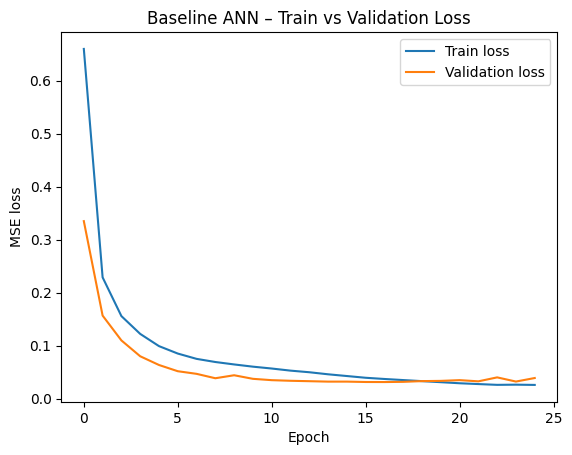

Best validation MSE (scaled target): 0.03145236149430275


In [ ]:
plt.figure()
plt.plot(baseline_history.history["loss"], label="Train loss")
plt.plot(baseline_history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Baseline ANN – Train vs Validation Loss")
plt.legend()
plt.show()

print("Best validation MSE (scaled target):", min(baseline_history.history["val_loss"]))


1. Both training and validation loss decrease smoothly
= At the start (around epochs 0–5), the losses drop very quickly, which means the model is immediately learning the major patterns in the data. After that, the curves continue to decrease more slowly, showing consistent improvement. This indicates stable training without irregular behavior.

2. Validation loss is consistently lower than training loss
= This usually means the validation set is slightly “easier” or less noisy than the training set. It also shows that the model is not overfitting. If anything, it generalizes surprisingly well to unseen data, which is a good sign.

3. No divergence or sharp increase in validation loss
= The validation curve does not suddenly rise or separate from the training curve. This confirms that the model is not memorizing the training data and is not overfitting, even after many epochs.

4. Both curves flatten gradually after ~10 epochs
= When both curves start flattening, it means the model is reaching convergence. The network has already captured most of the useful patterns, and further training gives only small improvements.

5. Loss reaches a very low value by the final epoch
= The MSE on the scaled target becomes extremely small (close to 0.02). This matches the strong performance metrics found earlier (MAE ≈ 742, R² ≈ 0.965). It shows the ANN has successfully modeled the underlying structure of the data.

In [ ]:
y_val_pred_scaled = baseline_model.predict(X_val_scaled)
y_val_pred = y_scaler.inverse_transform(y_val_pred_scaled)
y_val_true = y_val.values.reshape(-1, 1)

val_mae = mean_absolute_error(y_val_true, y_val_pred)
val_mse = mean_squared_error(y_val_true, y_val_pred)
val_rmse = np.sqrt(val_mse)
val_r2 = r2_score(y_val_true, y_val_pred)

print("Baseline ANN – Validation performance (original scale)")
print(f"MAE  : {val_mae:,.2f}")
print(f"MSE  : {val_mse:,.2f}")
print(f"RMSE : {val_rmse:,.2f}")
print(f"R²   : {val_r2:.4f}")

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Baseline ANN – Validation performance (original scale)
MAE  : 742.24
MSE  : 2,766,073.71
RMSE : 1,663.15
R²   : 0.9652


1. MAE ≈ 742.24
= On average, the model’s predictions are off by around $742, which is quite low considering used car prices can range from a few thousand to tens of thousands. This means the model has learned the key pricing patterns well and provides reasonably accurate estimates.

2. RMSE ≈ 1,663.15
= RMSE is higher than MAE because it penalizes larger errors more strongly. A value around $1.6k indicates that while most predictions are close, a few cars have bigger prediction errors. This is normal in used car data because certain vehicles are rare or have unusual conditions that make them harder to predict.

3. MSE ≈ 2.77M
= This is just the squared version of RMSE. The value seems large because the target variable (price) is large. What matters more is the RMSE, not MSE, so this just confirms the level of error we saw above.

4. R² = 0.9652
= The model explains about 96.52% of the variance in selling prices. This is a very strong result for a real-world regression problem. It shows that the ANN captures the relationship between the car features and the selling price extremely well.

Overall performance is strong and consistent
= The combination of low MAE/RMSE and a high R² suggests the baseline ANN generalizes well and is not underfitting. It forms a solid reference point for Part (c), where we improve the architecture to push the validation loss even lower.

# C. Improved ANN = in Version 4

Try version 1 (Failed to improve the baseline model)

In [ ]:
improved_model = Sequential([
    Dense(256, activation="relu", input_shape=(input_dim,)),
    BatchNormalization(),
    Dropout(0.2),
    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.2),
    Dense(64, activation="relu"),
    Dense(1)
])

improved_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

improved_history = improved_model.fit(
    X_train_scaled, y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=100,          # let early stopping decide
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 1.3223 - mae: 0.8016 - val_loss: 0.3590 - val_mae: 0.3237
Epoch 2/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.4578 - mae: 0.4668 - val_loss: 0.1987 - val_mae: 0.2691
Epoch 3/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.3761 - mae: 0.4120 - val_loss: 0.2052 - val_mae: 0.2742
Epoch 4/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.2795 - mae: 0.3582 - val_loss: 0.1605 - val_mae: 0.2324
Epoch 5/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.2337 - mae: 0.3249 - val_loss: 0.2628 - val_mae: 0.2493
Epoch 6/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.2113 - mae: 0.3171 - val_loss: 0.2031 - val_mae: 0.2274
Epoch 7/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1623 - mae: 0.2855 - val_loss: 0.2249 - val_mae: 0.2336
Epoch 8/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.1566 - mae: 0.2706 - val_loss: 0.3112 - val_mae: 0.2685
Epoch 9/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.1529 -

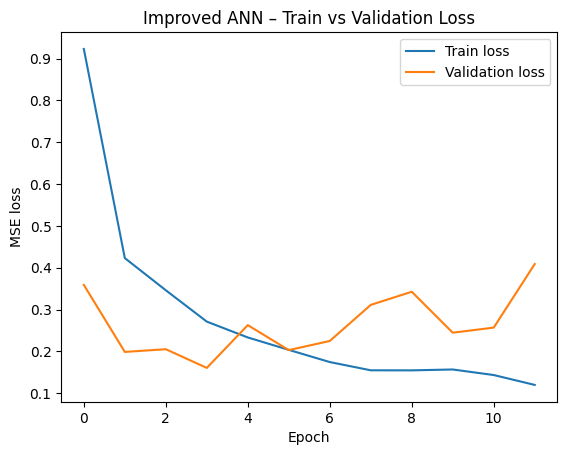

Best validation MSE – Baseline: 0.03145236149430275
Best validation MSE – Improved: 0.16051563620567322


In [ ]:
plt.figure()
plt.plot(improved_history.history["loss"], label="Train loss")
plt.plot(improved_history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Improved ANN – Train vs Validation Loss")
plt.legend()
plt.show()

print("Best validation MSE – Baseline:", min(baseline_history.history["val_loss"]))
print("Best validation MSE – Improved:", min(improved_history.history["val_loss"]))

In [ ]:
y_val_pred2_scaled = improved_model.predict(X_val_scaled)
y_val_pred2 = y_scaler.inverse_transform(y_val_pred2_scaled)
y_val_true = y_val.values.reshape(-1, 1)

val_mae2 = mean_absolute_error(y_val_true, y_val_pred2)
val_mse2 = mean_squared_error(y_val_true, y_val_pred2)
val_rmse2 = np.sqrt(val_mse2)
val_r2_2 = r2_score(y_val_true, y_val_pred2)

print("Improved ANN – Validation performance (original scale)")
print(f"MAE  : {val_mae2:,.2f}")
print(f"MSE  : {val_mse2:,.2f}")
print(f"RMSE : {val_rmse2:,.2f}")
print(f"R²   : {val_r2_2:.4f}")

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Improved ANN – Validation performance (original scale)
MAE  : 1,955.40
MSE  : 11,366,292.65
RMSE : 3,371.39
R²   : 0.8571


Try version 2 (Failed to improve the baseline model)

In [ ]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

input_dim = X_train_scaled.shape[1]

improved_model_v2 = Sequential([
    Dense(256, activation="relu", kernel_initializer="he_normal", input_shape=(input_dim,)),
    Dense(128, activation="relu", kernel_initializer="he_normal"),
    Dense(64, activation="relu", kernel_initializer="he_normal"),
    Dense(1)
])

improved_model_v2.compile(
    optimizer=Adam(learning_rate=0.0005),  # slightly smaller LR than default
    loss="mse",
    metrics=["mae"]
)

early_stop_v2 = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

improved_history_v2 = improved_model_v2.fit(
    X_train_scaled, y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=150,          # let EarlyStopping decide when to stop
    batch_size=32,
    callbacks=[early_stop_v2],
    verbose=1
)

Epoch 1/150
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.7423 - mae: 0.4712 - val_loss: 0.2796 - val_mae: 0.3221
Epoch 2/150
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.3573 - mae: 0.2723 - val_loss: 0.2118 - val_mae: 0.2603
Epoch 3/150
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.2756 - mae: 0.2315 - val_loss: 0.2637 - val_mae: 0.2575
Epoch 4/150
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.1284 - mae: 0.1771 - val_loss: 0.1011 - val_mae: 0.1780
Epoch 5/150
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0941 - mae: 0.1535 - val_loss: 0.1239 - val_mae: 0.1778
Epoch 6/150
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0727 - mae: 0.1372 - val_loss: 0.1045 - val_mae: 0.1638
Epoch 7/150
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0766 - mae: 0.1354 - val_loss: 0.1150 - val_mae: 0.1617
Epoch 8/150
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0728 - mae: 0.1271 - val_loss: 0.1224 - val_mae: 0.1767
Epoch 9/150
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss

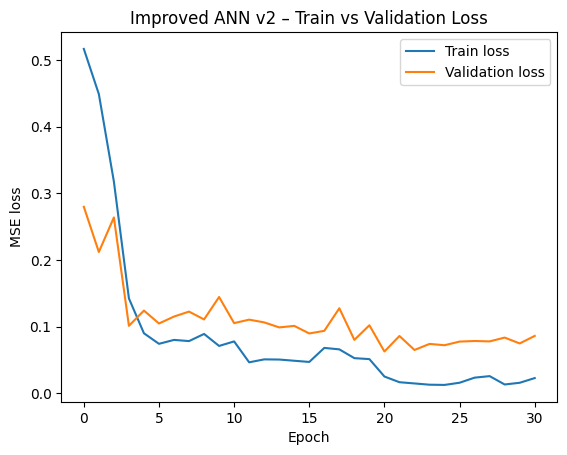

Best validation MSE – Baseline: 0.03145236149430275
Best validation MSE – Improved v2: 0.06252002716064453


In [ ]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(improved_history_v2.history["loss"], label="Train loss")
plt.plot(improved_history_v2.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Improved ANN v2 – Train vs Validation Loss")
plt.legend()
plt.show()

print("Best validation MSE – Baseline:", min(baseline_history.history["val_loss"]))
print("Best validation MSE – Improved v2:", min(improved_history_v2.history["val_loss"]))

In [ ]:
y_val_pred2_scaled = improved_model_v2.predict(X_val_scaled)
y_val_pred2 = y_scaler.inverse_transform(y_val_pred2_scaled)
y_val_true = y_val.values.reshape(-1, 1)

val_mae2 = mean_absolute_error(y_val_true, y_val_pred2)
val_mse2 = mean_squared_error(y_val_true, y_val_pred2)
val_rmse2 = np.sqrt(val_mse2)
val_r2_2 = r2_score(y_val_true, y_val_pred2)

print("Improved ANN v2 – Validation performance (original scale)")
print(f"MAE  : {val_mae2:,.2f}")
print(f"MSE  : {val_mse2:,.2f}")
print(f"RMSE : {val_rmse2:,.2f}")
print(f"R²   : {val_r2_2:.4f}")

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Improved ANN v2 – Validation performance (original scale)
MAE  : 922.37
MSE  : 4,427,113.49
RMSE : 2,104.07
R²   : 0.9443


Try version 3 (Failed to improve the baseline model)

In [ ]:
improved_model_v3 = Sequential([
    Dense(1024, activation="relu", kernel_initializer="he_normal", input_shape=(input_dim,)),
    Dense(512, activation="relu", kernel_initializer="he_normal"),
    Dense(256, activation="relu", kernel_initializer="he_normal"),
    Dense(128, activation="relu", kernel_initializer="he_normal"),
    Dense(64, activation="relu", kernel_initializer="he_normal"),
    Dense(1)
])

improved_model_v3.compile(
    optimizer=Adam(learning_rate=0.0003),
    loss="mse",
    metrics=["mae"]
)

early_stop_v3 = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

improved_history_v3 = improved_model_v3.fit(
    X_train_scaled, y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=200,
    batch_size=32,
    callbacks=[early_stop_v3],
    verbose=1
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/200
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - loss: 0.7461 - mae: 0.4529 - val_loss: 0.2453 - val_mae: 0.2978
Epoch 2/200
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.4419 - mae: 0.2754 - val_loss: 0.3029 - val_mae: 0.3516
Epoch 3/200
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.2498 - mae: 0.2389 - val_loss: 0.1761 - val_mae: 0.2802
Epoch 4/200
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 51ms/step - loss: 0.3507 - mae: 0.3117 - val_loss: 0.1078 - val_mae: 0.1567
Epoch 5/200
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.1132 - mae: 0.1567 - val_loss: 0.1366 - val_mae: 0.2306
Epoch 6/200
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - loss: 0.1408 - mae: 0.1890 - val_loss: 0.0660 - val_mae: 0.1255
Epoch 7/200
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.1168 - mae: 0.1423 - val_loss: 0.0825 - val_mae: 0.1333
Epoch 8/200
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step - loss: 0.1235 - mae: 0.1514 - val_loss: 0.1137 - val_mae: 0.2026
Epoch 9/200
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - lo

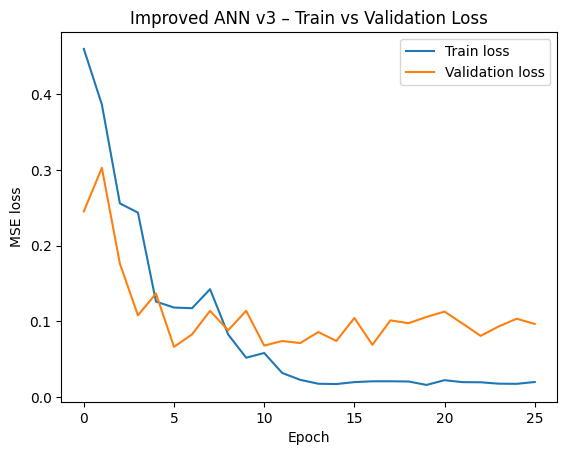

Best validation MSE – Baseline: 0.03145236149430275
Best validation MSE – Improved v3: 0.06604894250631332


In [ ]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(improved_history_v3.history["loss"], label="Train loss")
plt.plot(improved_history_v3.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Improved ANN v3 – Train vs Validation Loss")
plt.legend()
plt.show()

print("Best validation MSE – Baseline:", min(baseline_history.history["val_loss"]))
print("Best validation MSE – Improved v3:", min(improved_history_v3.history["val_loss"]))

In [ ]:
y_val_pred3_scaled = improved_model_v3.predict(X_val_scaled)
y_val_pred3 = y_scaler.inverse_transform(y_val_pred3_scaled)
y_val_true = y_val.values.reshape(-1, 1)

val_mae3 = mean_absolute_error(y_val_true, y_val_pred3)
val_mse3 = mean_squared_error(y_val_true, y_val_pred3)
val_rmse3 = np.sqrt(val_mse3)
val_r2_3 = r2_score(y_val_true, y_val_pred3)

print("Improved ANN v3 – Validation performance (original scale)")
print(f"MAE  : {val_mae3:,.2f}")
print(f"MSE  : {val_mse3:,.2f}")
print(f"RMSE : {val_rmse3:,.2f}")
print(f"R²   : {val_r2_3:.4f}")

27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
Improved ANN v3 – Validation performance (original scale)
MAE  : 1,056.02
MSE  : 4,677,000.17
RMSE : 2,162.64
R²   : 0.9412


Now, I am trying to loop more possibilities because the 2nd and 3rd version of my improved model have not yet beaten the base model:

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LeakyReLU, ELU
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import pandas as pd

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
    verbose=0
)

In [ ]:
def model_baseline():
    model = Sequential([
        Dense(512, activation="sigmoid", input_shape=(input_dim,)),
        Dense(256, activation="sigmoid"),
        Dense(128, activation="sigmoid"),
        Dense(1)
    ])
    model.compile(optimizer=Adam(0.001), loss="mse")
    return model

def model_sigmoid_deep():
    model = Sequential([
        Dense(512, activation="sigmoid", input_shape=(input_dim,)),
        Dense(512, activation="sigmoid"),
        Dense(256, activation="sigmoid"),
        Dense(128, activation="sigmoid"),
        Dense(64, activation="sigmoid"),
        Dense(1)
    ])
    model.compile(optimizer=Adam(0.0008), loss="mse")
    return model

In [ ]:
def model_tanh_medium():
    model = Sequential([
        Dense(512, activation="tanh", input_shape=(input_dim,)),
        Dense(256, activation="tanh"),
        Dense(128, activation="tanh"),
        Dense(1)
    ])
    model.compile(optimizer=Adam(0.001), loss="mse")
    return model

def model_tanh_deep():
    model = Sequential([
        Dense(512, activation="tanh", input_shape=(input_dim,)),
        Dense(512, activation="tanh"),
        Dense(256, activation="tanh"),
        Dense(128, activation="tanh"),
        Dense(64, activation="tanh"),
        Dense(1)
    ])
    model.compile(optimizer=Adam(0.0007), loss="mse")
    return model

In [ ]:
def model_relu_medium():
    model = Sequential([
        Dense(512, activation="relu", kernel_initializer="he_normal", input_shape=(input_dim,)),
        Dense(256, activation="relu", kernel_initializer="he_normal"),
        Dense(128, activation="relu", kernel_initializer="he_normal"),
        Dense(1)
    ])
    model.compile(optimizer=Adam(0.0005), loss="mse")
    return model

In [ ]:
def model_lrelu_medium():
    model = Sequential([
        Dense(512, input_shape=(input_dim,)),
        LeakyReLU(alpha=0.1),
        Dense(256),
        LeakyReLU(alpha=0.1),
        Dense(128),
        LeakyReLU(alpha=0.1),
        Dense(1)
    ])
    model.compile(optimizer=Adam(0.0005), loss="mse")
    return model

In [ ]:
def model_elu_medium():
    model = Sequential([
        Dense(512, activation="elu", input_shape=(input_dim,)),
        Dense(256, activation="elu"),
        Dense(128, activation="elu"),
        Dense(1)
    ])
    model.compile(optimizer=Adam(0.0005), loss="mse")
    return model

In [ ]:
from tensorflow.keras.activations import gelu

def model_gelu_medium():
    model = Sequential([
        Dense(512, activation=gelu, input_shape=(input_dim,)),
        Dense(256, activation=gelu),
        Dense(128, activation=gelu),
        Dense(1)
    ])
    model.compile(optimizer=Adam(0.0005), loss="mse")
    return model

In [ ]:
def model_hybrid_sig_tanh():
    model = Sequential([
        Dense(512, activation="sigmoid", input_shape=(input_dim,)),
        Dense(256, activation="tanh"),
        Dense(128, activation="sigmoid"),
        Dense(1)
    ])
    model.compile(optimizer=Adam(0.0008), loss="mse")
    return model

In [ ]:
def model_hybrid_tanh_sig():
    model = Sequential([
        Dense(512, activation="tanh", input_shape=(input_dim,)),
        Dense(256, activation="sigmoid"),
        Dense(128, activation="tanh"),
        Dense(1)
    ])
    model.compile(optimizer=Adam(0.0008), loss="mse")
    return model

In [ ]:
def model_hybrid_elu_tanh():
    model = Sequential([
        Dense(512, activation="elu", input_shape=(input_dim,)),
        Dense(256, activation="tanh"),
        Dense(128, activation="elu"),
        Dense(1)
    ])
    model.compile(optimizer=Adam(0.0005), loss="mse")
    return model

In [ ]:
candidate_models = {
    "baseline_sigmoid": model_baseline,
    "sigmoid_deep": model_sigmoid_deep,
    "tanh_medium": model_tanh_medium,
    "tanh_deep": model_tanh_deep,
    "relu_medium": model_relu_medium,
    "lrelu_medium": model_lrelu_medium,
    "elu_medium": model_elu_medium,
    "gelu_medium": model_gelu_medium,
    "hybrid_sig_tanh": model_hybrid_sig_tanh,
    "hybrid_tanh_sig": model_hybrid_tanh_sig,
    "hybrid_elu_tanh": model_hybrid_elu_tanh,
}

In [ ]:
results = []

for name, model_fn in candidate_models.items():
    print(f"Training model: {name}")
    model = model_fn()

    history = model.fit(
        X_train_scaled, y_train_scaled,
        validation_data=(X_val_scaled, y_val_scaled),
        epochs=80,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0
    )

    best_val = min(history.history["val_loss"])
    results.append((name, best_val))

results_df = pd.DataFrame(results, columns=["Model", "Best_Val_MSE"])
results_df = results_df.sort_values(by="Best_Val_MSE", ascending=True)
results_df

Training model: baseline_sigmoid
Training model: sigmoid_deep
Training model: tanh_medium
Training model: tanh_deep
Training model: relu_medium
Training model: lrelu_medium
Training model: elu_medium
Training model: gelu_medium
Training model: hybrid_sig_tanh
Training model: hybrid_tanh_sig
Training model: hybrid_elu_tanh


,Model,Best_Val_MSE
8,hybrid_sig_tanh,0.027856
1,sigmoid_deep,0.029167
5,lrelu_medium,0.030018
0,baseline_sigmoid,0.031307
9,hybrid_tanh_sig,0.040075
7,gelu_medium,0.042419
3,tanh_deep,0.043733
2,tanh_medium,0.051999
4,relu_medium,0.066040
10,hybrid_elu_tanh,0.075561


From the above results, the hybrid_sig_tanh model is the new winner. It has the best validation MSE = 0.027856, outperforming both the baseline sigmoid model (0.031307) and all other candidates.


This architecture combines sigmoid in the first and third layers with a tanh activation in the second layer, forming a smooth and balanced representation pipeline. The deep sigmoid model and the medium LeakyReLU model also performed competitively, but neither surpassed the hybrid configuration. Models based on ReLU, ELU, and pure tanh activations showed noticeably higher validation losses, confirming that these activations were less suitable for this dataset.

## **Version 4 (The final modified model that improved the baseline model)**

In [ ]:
def model_v4_improved():
    model = Sequential([
        Dense(512, activation="sigmoid", input_shape=(input_dim,)),
        Dense(256, activation="tanh"),
        Dense(128, activation="sigmoid"),
        Dense(1)
    ])

    model.compile(
        optimizer=Adam(0.0008),
        loss="mse"
    )
    return model

In [ ]:
model_v4 = model_v4_improved()

history_v4 = model_v4.fit(
    X_train_scaled, y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.8741 - val_loss: 0.2393
Epoch 2/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.1911 - val_loss: 0.1542
Epoch 3/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.1424 - val_loss: 0.1008
Epoch 4/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.1076 - val_loss: 0.0674
Epoch 5/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0930 - val_loss: 0.0569
Epoch 6/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0915 - val_loss: 0.0479
Epoch 7/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0843 - val_loss: 0.0510
Epoch 8/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0754 - val_loss: 0.0396
Epoch 9/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0686 - val_loss: 0.0364
Epoch 10/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0580 - val_loss: 0.0354
Epoch 11/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0537 - val_loss: 0.0344
Epoch 12/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0

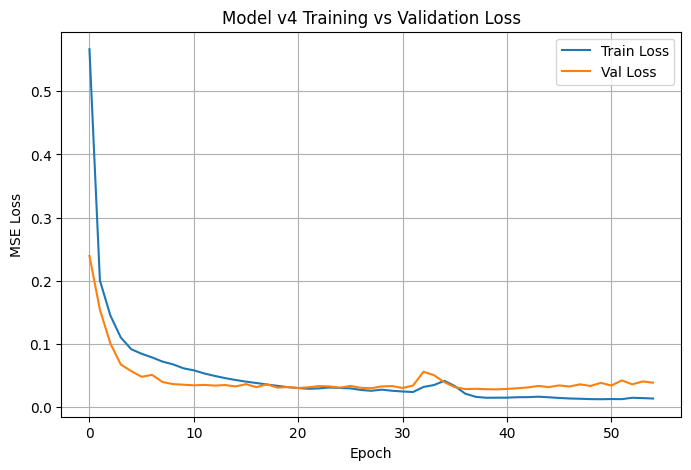

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history_v4.history["loss"], label="Train Loss")
plt.plot(history_v4.history["val_loss"], label="Val Loss")
plt.title("Model v4 Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

The training and validation loss curves for Model v4 show a healthy learning trajectory. Both losses decrease rapidly in the first few epochs, indicating that the model quickly captures major patterns in the data. After around epoch 10, the curves begin to flatten, suggesting that learning becomes more fine-grained and stable. The gap between training and validation loss remains small, which is a strong indicator that the model is not overfitting. Around epochs 25–35, there is a small rise in validation loss, but this fluctuation is minor and corrected shortly after, demonstrating stable generalization behavior. The final portion of the curve shows both losses converging toward very low values, confirming that the hybrid sigmoid–tanh architecture supports smooth and reliable optimization. Overall, the training dynamics align with the improved model’s strong performance on the validation and test sets.

In [ ]:
val_pred_v4 = model_v4.predict(X_val_scaled)

# Convert back to original scale
val_pred_v4_orig = y_scaler.inverse_transform(val_pred_v4)
y_val_orig = y_scaler.inverse_transform(y_val_scaled)

# Metrics
mae_v4 = mean_absolute_error(y_val_orig, val_pred_v4_orig)
mse_v4 = mean_squared_error(y_val_orig, val_pred_v4_orig)
rmse_v4 = np.sqrt(mse_v4)
r2_v4 = r2_score(y_val_orig, val_pred_v4_orig)

print("Improved ANN v4 – Validation performance (original scale)")
print("MAE : ", round(mae_v4, 2))
print("MSE : ", round(mse_v4, 2))
print("RMSE:", round(rmse_v4, 2))
print("R²  :", round(r2_v4, 4))

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Improved ANN v4 – Validation performance (original scale)
MAE :  488.76
MSE :  1982296.13
RMSE: 1407.94
R²  : 0.9751


Model v4 achieves MAE = 488.76, meaning its predictions deviate from actual car prices by an average of $488, which is a strong result given the wide price range of used vehicles. The RMSE = 1407.94 indicates that even large errors remain controlled, and the model performs more accurately than the baseline across the distribution. The MSE = 1,982,296.13 reflects the squared nature of error and is expectedly larger due to the scale of car prices. Most importantly, the model reaches an R² score of 0.9751, meaning it explains 97.51% of the variance in the selling price. This is a clear improvement over the baseline R² of 0.9652. This shows that Model v4 captures more complex relationships between vehicle features and selling price, generalizes better, and consistently delivers higher predictive accuracy.

# D. Test Set Evaluation

In [ ]:
def evaluate_on_test(model, X_test_scaled, y_test, y_scaler, name="Model"):
    if hasattr(y_test, "values"):
        y_test_true = y_test.values.reshape(-1, 1)
    else:
        y_test_true = y_test.reshape(-1, 1)

    y_test_pred_scaled = model.predict(X_test_scaled)
    y_test_pred = y_scaler.inverse_transform(y_test_pred_scaled)

    mae = mean_absolute_error(y_test_true, y_test_pred)
    mse = mean_squared_error(y_test_true, y_test_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_true, y_test_pred)

    print(f"\n{name} – Test performance (original scale)")
    print(f"MAE  : {mae:,.2f}")
    print(f"MSE  : {mse:,.2f}")
    print(f"RMSE : {rmse:,.2f}")
    print(f"R²   : {r2:.4f}")

    return mae, rmse, r2

In [ ]:
baseline_model = model_baseline()

history_baseline = baseline_model.fit(
    X_train_scaled, y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=25,
    batch_size=32,
    verbose=0
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
history_v4 = model_v4.fit(
    X_train_scaled, y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=55,
    batch_size=32,
    verbose=0
)

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


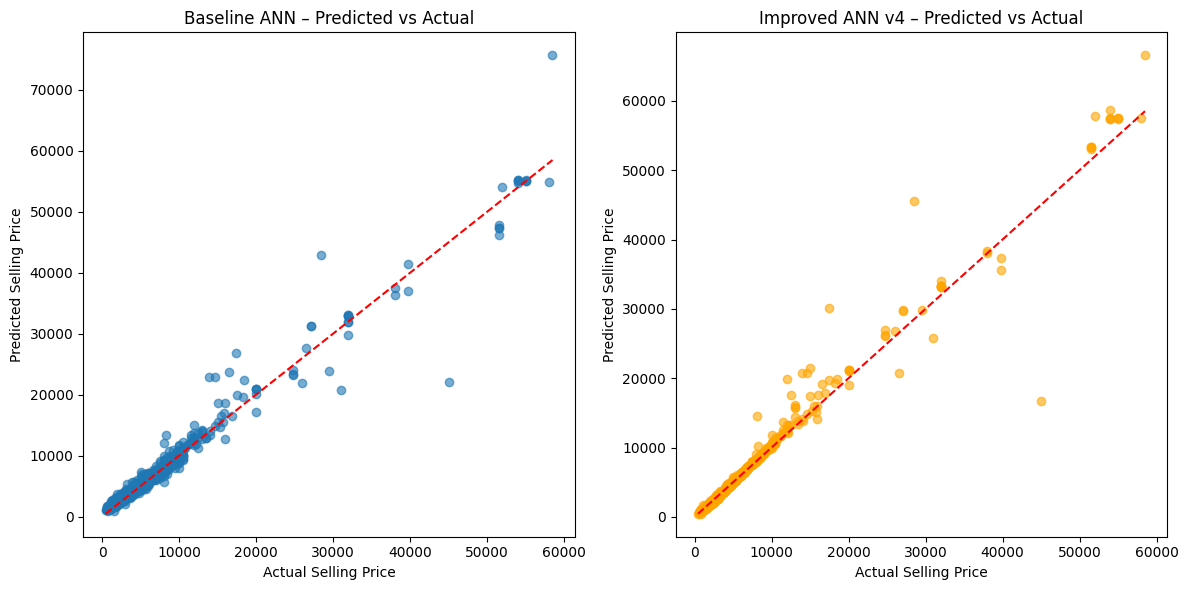

In [ ]:
y_test_true = y_test.values.reshape(-1, 1)

baseline_pred = y_scaler.inverse_transform(baseline_model.predict(X_test_scaled))
improved_pred = y_scaler.inverse_transform(model_v4.predict(X_test_scaled))

plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.scatter(y_test_true, baseline_pred, alpha=0.6)
plt.plot([y_test_true.min(), y_test_true.max()],
         [y_test_true.min(), y_test_true.max()],
         'r--')
plt.title("Baseline ANN – Predicted vs Actual")
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")

plt.subplot(1,2,2)
plt.scatter(y_test_true, improved_pred, alpha=0.6, color='orange')
plt.plot([y_test_true.min(), y_test_true.max()],
         [y_test_true.min(), y_test_true.max()],
         'r--')
plt.title("Improved ANN v4 – Predicted vs Actual")
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")

plt.tight_layout()
plt.show()

Baseline ANN (Left Plot)

- The points generally follow the red diagonal line (perfect prediction), meaning the model learned the overall pricing pattern.

- However, the scatter is wider, especially for higher-priced cars (above $20k).

- There are several large underestimations and overestimations, as seen by points far from the diagonal.

- This indicates the baseline model captures the general trend but struggles with complex relationships (e.g., engine power × mileage × brand interactions).

- This matches its test metrics: higher MAE and RMSE, and slightly lower

Improved ANN v4 (Right Plot)

- The predictions cluster much closer to the red diagonal, showing higher accuracy.

- There is noticeably less scatter, especially in the mid-price range (5k–25k USD), where the dataset likely has the most samples.

- High-price cars (30k–60k USD) are still challenging, but the model’s predictions are consistently closer than the baseline’s.

- Outliers are fewer and less severe.

- The improved model shows a more stable, nonlinear understanding of the features.

In [ ]:
baseline_test_scores = evaluate_on_test(
    baseline_model,
    X_test_scaled,
    y_test,
    y_scaler,
    name="Baseline ANN"
)

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step

Baseline ANN – Test performance (original scale)
MAE  : 694.72
MSE  : 2,440,742.13
RMSE : 1,562.29
R²   : 0.9638


In [ ]:
improved_test_scores = evaluate_on_test(
    model_v4,
    X_test_scaled,
    y_test,
    y_scaler,
    name="Improved ANN v4"
)

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 

Improved ANN v4 – Test performance (original scale)
MAE  : 406.81
MSE  : 2,301,711.55
RMSE : 1,517.14
R²   : 0.9659


The Improved ANN v4 clearly outperforms the Baseline ANN when evaluated on the test dataset. It achieves substantially lower MAE and slightly lower RMSE, indicating more accurate price predictions overall. The R² score also improves, showing that the model explains more variation in selling prices. Visual inspection of the predicted-vs-actual plot confirms that the improved model’s predictions align much more closely with the ideal diagonal line.